[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KuBaN658/materials/blob/main/seminars/bert_practice/bert_practice%201126.ipynb)

## План занятия

1. Данные и постановка задачи
2. Токенизация и батчи
3. Baseline: RuBERT + голова-классификатор
4. Визуализация эмбеддингов: t-SNE
5. Задание: Классификация тональности твитов
6. Немного GPT: генерация текста


In [1]:
import random
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.manifold import TSNE

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    GenerationConfig,
    get_linear_schedule_with_warmup,
    pipeline,
)

# Фиксируем seed, чтобы эксперименты были воспроизводимыми
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Выбираем устройство: CUDA (Colab/GPU) → MPS (Apple Silicon) → CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif (
    getattr(torch.backends, "mps", None) is not None
    and torch.backends.mps.is_available()
):
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Устройство: {device}")

# Стиль графиков
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
    }
)


Устройство: mps


## 1. Данные и постановка задачи

**Задача:** по короткому **заголовку** русской новости предсказать одну из 4 рубрик (Россия / Мир / Спорт / Экономика).

Почему не учим Transformer с нуля? Нужны миллионы текстов и огромный compute. Берём **pretrained** RuBERT (уже «знает русский язык») и доучиваем под нашу задачу.

**Метрики:** accuracy (доля верных ответов) и **macro-F1** (среднее F1 по классам). При дисбалансе классов F1 часто важнее accuracy.

In [2]:
# Русские новости (Lenta/RIA и др.): берём короткие заголовки, без пакета datasets.
# Если файла нет в текущей папке — скачиваем с Google Drive.
DATA_PATH = Path("data/news.csv")
FILE_ID = "1dO35ScSr0EwYoRApiWq5ftAA8kJ7EGFN"
DATA_URL = f"https://drive.google.com/uc?export=download&id={FILE_ID}&confirm=t"

DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    print("Скачиваем news.csv с Google Drive (~77 МБ) ...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Готово:", DATA_PATH.resolve())
else:
    print("Файл уже есть:", DATA_PATH.resolve())

news = pd.read_csv(DATA_PATH)

# Оставляем 4 популярные рубрики
TOP_RUBRICS = ["Россия", "Мир", "Спорт", "Экономика"]
raw = (
    news.dropna(subset=["title", "rubric"])
    .drop_duplicates(subset=["title"])
    .loc[lambda d: d["rubric"].isin(TOP_RUBRICS)]
    .copy()
)
# Текст для модели — только заголовок
raw["text"] = raw["title"].astype(str).str.strip()
LABEL_NAMES = {i: name for i, name in enumerate(TOP_RUBRICS)}
name_to_id = {v: k for k, v in LABEL_NAMES.items()}
raw["label"] = raw["rubric"].map(name_to_id).astype(int)
raw["label_name"] = raw["rubric"]

print("Заголовков в топ-4 рубриках:", len(raw))
print(
    "Длина заголовка (символы): медиана =", int(raw["text"].str.len().median())
)
print(raw["label_name"].value_counts())
raw[["text", "label_name"]].sample(5)

Файл уже есть: /Users/father/Desktop/materials/seminars/bert_practice/data/news.csv
Заголовков в топ-4 рубриках: 2536
Длина заголовка (символы): медиана = 59
label_name
Россия       904
Мир          718
Спорт        494
Экономика    420
Name: count, dtype: int64


,text,label_name
2978,«Россети» взяли под особый контроль электросна...,Экономика
462,Названа возможная причина смерти ребенка в зах...,Россия
1056,В России запустили обучающую программу по выяв...,Россия
4235,Sberbank Private Banking победил в международн...,Экономика
3777,Боец MMA «выключила» соперницу ударом ногой в ...,Спорт


In [3]:
MAX_LENGTH = 32  # заголовки короткие: 32 токенов хватает с запасом

# Стратификация по классу — как в полной выборке
train_df, val_df = train_test_split(
    raw,
    train_size=0.75,
    stratify=raw["label"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Train:", len(train_df), "| Val:", len(val_df))
print("Баланс train:")
print(train_df["label_name"].value_counts())
print("\nПример заголовка:")
print(train_df.loc[0, "text"])


Train: 1902 | Val: 634
Баланс train:
label_name
Россия       678
Мир          538
Спорт        371
Экономика    315
Name: count, dtype: int64

Пример заголовка:
Число жертв коронавируса в Италии превысило 20 тысяч


## 2. Токенизация и батчи

**Мотивация.** Модель не читает слова как человек: она видит целые числа — id токенов.

**Как работает алгоритм.**
1. `AutoTokenizer` режет текст на subword-токены (WordPiece у BERT/RuBERT).
2. В начало ставится спецтокен `[CLS]`, в конец — `[SEP]`.
3. Токены превращаются в `input_ids`; `attention_mask` помечает реальные токены единицей, а padding — нулём.
4. `truncation=True` обрезает слишком длинные тексты, а `padding="max_length"` дополняет каждую последовательность до `max_length`, чтобы в батче у всех была одна длина.

**Когда применять.**
- Хорошо подходит, когда дообучаете готовую модель: нужен **тот же** tokenizer, что у чекпоинта.
- Плохо подходит, когда tokenizer взят от другой модели: id токенов не совпадут с эмбеддингами.


In [4]:
# Имя чекпоинта: tokenizer и модель должны быть из одной семьи
MODEL_NAME = "cointegrated/rubert-tiny2"
# На Apple MPS: SDPA + dropout в train даёт NotImplementedError → eager attention
MODEL_LOAD_KWARGS = {"attn_implementation": "eager"}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Смотрим один пример «до / после» — так проще понять, что уходит в модель
example = train_df.loc[0, "text"]
encoded = tokenizer(
    example,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors=None,  # пока обычные списки Python, не тензоры
)

tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
print("Заголовок:", example, "\n")
print("Первые 20 токенов:", tokens[:20])
print("input_ids (начало):", encoded["input_ids"][:20])
print("attention_mask (начало):", encoded["attention_mask"][:20])
print("Длина последовательности:", len(encoded["input_ids"]), "(= max_length)")
# Сколько реальных (не pad) токенов занял заголовок
n_real = int(sum(encoded["attention_mask"]))
print(
    f"Реальных токенов (без padding): {n_real} — заголовки обычно укладываются с запасом"
)

Заголовок: Число жертв коронавируса в Италии превысило 20 тысяч 

Первые 20 токенов: ['[CLS]', 'Число', 'жертв', 'коронавируса', 'в', 'Италии', 'превысило', '20', 'тысяч', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
input_ids (начало): [2, 34205, 28198, 29623, 314, 11348, 39761, 619, 7906, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask (начало): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Длина последовательности: 32 (= max_length)
Реальных токенов (без padding): 10 — заголовки обычно укладываются с запасом


In [5]:
class NewsDataset(Dataset):
    """Обёртка над таблицей текстов: на каждом __getitem__ токенизируем один пример."""

    def __init__(self, frame: pd.DataFrame, tokenizer, max_length: int = 64):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        # padding="max_length": все примеры одной длины → простой collate в DataLoader
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt",
        )
        # tokenizer вернул batch-размерность 1 — снимаем её squeeze(0)
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


BATCH_SIZE = 16

train_ds = NewsDataset(train_df, tokenizer, MAX_LENGTH)
val_ds = NewsDataset(val_df, tokenizer, MAX_LENGTH)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

# Проверяем форму батча: [B, L] для ids/mask и [B] для меток
batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k}: shape={tuple(v.shape)}, dtype={v.dtype}")

input_ids: shape=(16, 32), dtype=torch.int64
token_type_ids: shape=(16, 32), dtype=torch.int64
attention_mask: shape=(16, 32), dtype=torch.int64
labels: shape=(16,), dtype=torch.int64


## 3. Baseline: RuBERT + голова-классификатор

**Мотивация.** На лекции: текст → BERT → вектор `[CLS]` → линейная голова → класс. Сейчас собираем минимальный рабочий цикл обучения и получаем первые метрики — без трюков.

**Как работает алгоритм.**
1. `AutoModelForSequenceClassification` загружает pretrained-тело и сразу вешает классификационную голову на `num_labels` классов.
2. На каждом шаге считаем cross-entropy между логитами и меткой класса.
3. Обновляем веса через AdamW. Для full fine-tune learning rate маленький, $2\cdot 10^{-5}$ … $5\cdot 10^{-5}$: так не ломаются pretrained-веса. Если тело заморожено и учится только новая голова, lr больше — в коде $10^{-3}$.
4. Freeze и full fine-tune — два отдельных прогона с одного чекпоинта, а не продолжение одного обучения. В freeze градиент есть только у головы. В full fine-tune разморожены все слои.

**Когда применять.**
- Хорошо подходит, когда: задача — **закрытый набор классов** (тональность, тема, тип тикета), есть хотя бы сотни размеченных примеров, а язык/домен близки к предобучению модели. Pretrained-тело даёт сильный старт: даже короткий fine-tune обычно обгоняет TF-IDF «с нуля».
- Плохо подходит / есть альтернативы, когда: размеченных текстов единицы–десятки (модель легко переобучится) — тогда часто выгоднее классические признаки (TF-IDF + логрег) или few-shot у большой языковой модели; если нужен не класс, а свободный ответ/генерация.


In [6]:
NUM_LABELS = 4
EPOCHS_FREEZE = 5
EPOCHS_FULL = 5
LR_FREEZE = 1e-3
LR_FULL = 2e-5
WEIGHT_DECAY = 0.001


def set_requires_grad(model, requires_grad: bool):
    """Включает/выключает градиенты у всех параметров модели."""
    for p in model.parameters():
        p.requires_grad = requires_grad


def evaluate(model, loader):
    """Считает loss, accuracy и macro-F1 на loader (режим eval, без градиентов).

    Loss — cross-entropy модели, без label smoothing. Так val и test сравнимы
    между собой, даже если в train_epochs сглаживание включено.
    """
    model.eval()
    losses = []
    y_true, y_pred = [], []
    # На валидации градиенты не нужны — экономим память и время
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(**batch)
            losses.append(out.loss.item())
            preds = out.logits.argmax(dim=-1)
            y_true.extend(batch["labels"].cpu().tolist())
            y_pred.extend(preds.cpu().tolist())
    return {
        "loss": float(np.mean(losses)),
        "acc": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, average="macro"),
    }


def train_epochs(
    model,
    train_loader,
    val_loader,
    epochs,
    lr,
    label_smoothing=0.0,
    use_scheduler=False,
):
    """Учебный цикл обучения.

    Возвращает метрики по эпохам и lr на каждом шаге.
    train_loss считается своим CrossEntropyLoss: при label_smoothing > 0 он сглажен.
    val_loss из evaluate — обычная cross-entropy без сглаживания.
    Эти два loss при сглаживании сравнивать нельзя; для выбора модели смотрите val macro-F1.
    """
    # Берём только параметры, у которых requires_grad=True (важно для freeze)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)

    # Свой CE, чтобы включать label_smoothing.
    # val/test loss в evaluate считается без сглаживания, его с train_loss не сравнивают.
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    total_steps = epochs * len(train_loader)
    scheduler = None
    if use_scheduler:
        # warmup на первые 10% шагов, затем linear decay — мягкий старт для pretrained-весов
        warmup_steps = max(1, int(0.1 * total_steps))
        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps,
        )
        print(
            f"Scheduler: warmup_steps={warmup_steps}, total_steps={total_steps}"
        )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "lr": [],
    }

    for epoch in range(1, epochs + 1):
        model.train()
        running = []
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            optimizer.zero_grad()
            out = model(**batch)  # логиты [B, num_labels]
            loss = criterion(out.logits, labels)
            loss.backward()
            # Клиппинг градиента — страховка от редких взрывных шагов
            nn.utils.clip_grad_norm_(params, max_norm=1.0)
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
                history["lr"].append(scheduler.get_last_lr()[0])
            else:
                history["lr"].append(lr)

            running.append(loss.item())

        val_m = evaluate(model, val_loader)
        history["train_loss"].append(float(np.mean(running)))
        history["val_loss"].append(val_m["loss"])
        history["val_acc"].append(val_m["acc"])
        history["val_f1"].append(val_m["f1"])
        print(
            f"epoch {epoch}/{epochs} | train_loss={history['train_loss'][-1]:.4f} | "
            f"val_loss={val_m['loss']:.4f} | val_acc={val_m['acc']:.3f} | val_f1={val_m['f1']:.3f}"
        )

    return history


In [7]:
# --- Режим 1: freeze backbone, учим только классификационную голову ---
model_freeze = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, **MODEL_LOAD_KWARGS
).to(device)

# Замораживаем всё тело; голову (classifier) оставляем обучаемой
set_requires_grad(model_freeze, False)
for p in model_freeze.classifier.parameters():
    p.requires_grad = True

n_trainable = sum(
    p.numel() for p in model_freeze.parameters() if p.requires_grad
)
n_total = sum(p.numel() for p in model_freeze.parameters())
print(f"Trainable params (freeze): {n_trainable:,} / {n_total:,}")

hist_freeze = train_epochs(
    model_freeze,
    train_loader,
    val_loader,
    epochs=EPOCHS_FREEZE,
    lr=LR_FREEZE,
    label_smoothing=0.0,
    use_scheduler=False,
)
print("Итог freeze: val_f1 =", round(hist_freeze["val_f1"][-1], 3))

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable params (freeze): 1,252 / 29,195,020
epoch 1/5 | train_loss=1.2096 | val_loss=1.0499 | val_acc=0.677 | val_f1=0.651
epoch 2/5 | train_loss=0.9982 | val_loss=0.8855 | val_acc=0.759 | val_f1=0.759
epoch 3/5 | train_loss=0.8729 | val_loss=0.7850 | val_acc=0.779 | val_f1=0.782
epoch 4/5 | train_loss=0.7951 | val_loss=0.7158 | val_acc=0.790 | val_f1=0.793
epoch 5/5 | train_loss=0.7372 | val_loss=0.6668 | val_acc=0.803 | val_f1=0.804
Итог freeze: val_f1 = 0.804


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable params (full): 29,195,020
epoch 1/5 | train_loss=1.2231 | val_loss=1.0016 | val_acc=0.705 | val_f1=0.652
epoch 2/5 | train_loss=0.8025 | val_loss=0.5908 | val_acc=0.853 | val_f1=0.851
epoch 3/5 | train_loss=0.4851 | val_loss=0.4198 | val_acc=0.879 | val_f1=0.880
epoch 4/5 | train_loss=0.3371 | val_loss=0.3520 | val_acc=0.891 | val_f1=0.892
epoch 5/5 | train_loss=0.2563 | val_loss=0.3281 | val_acc=0.893 | val_f1=0.894
Итог full fine-tune: val_f1 = 0.894


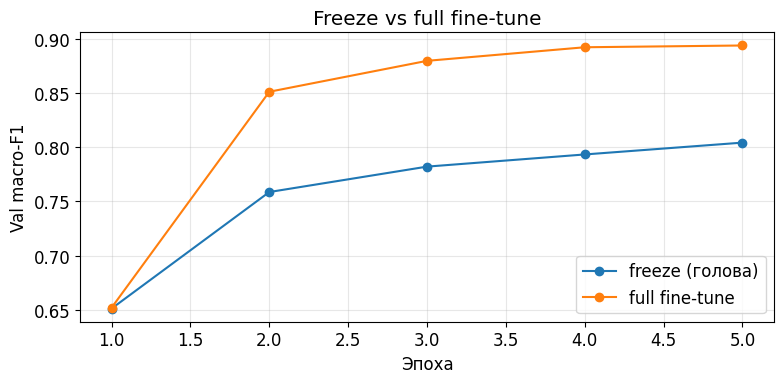

In [8]:
# --- Режим 2: full fine-tune — размораживаем все слои ---
model_ft = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, **MODEL_LOAD_KWARGS
).to(device)
set_requires_grad(model_ft, True)

n_trainable = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
print(f"Trainable params (full): {n_trainable:,}")

hist_ft = train_epochs(
    model_ft,
    train_loader,
    val_loader,
    epochs=EPOCHS_FULL,
    lr=LR_FULL,
    label_smoothing=0.0,
    use_scheduler=False,
)
print("Итог full fine-tune: val_f1 =", round(hist_ft["val_f1"][-1], 3))

# Сравниваем два режима на одном графике
fig, ax = plt.subplots()
ax.plot(
    range(1, len(hist_freeze["val_f1"]) + 1),
    hist_freeze["val_f1"],
    marker="o",
    label="freeze (голова)",
)
ax.plot(
    range(1, len(hist_ft["val_f1"]) + 1),
    hist_ft["val_f1"],
    marker="o",
    label="full fine-tune",
)
ax.set_xlabel("Эпоха")
ax.set_ylabel("Val macro-F1")
ax.set_title("Freeze vs full fine-tune")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Визуализация эмбеддингов: t-SNE

**Мотивация.** Одно число F1 не объясняет, *какие* классы путаются. Если достать вектор `[CLS]` и спроецировать в 2D, видно: разделились ли классы в пространстве представлений.

**Как работает алгоритм.**
1. Прогоняем тексты через энкодер **без** классификационной головы и берём hidden state токена `[CLS]` (позиция 0).
2. Получаем вектор высокой размерности (у `rubert-tiny2` — 312).
3. `TSNE` сжимает его в 2D, стараясь сохранить локальные окрестности точек.
4. Рисуем два графика: **до** fine-tuning (сырой pretrained) и **после**.

**Когда применять.**
- Хорошо подходит, когда: хотите диагностику ошибок, поиск похожих примеров, быстрый sanity-check «выучила ли модель структуру».
- Плохо подходит, когда: точек мало (<50) — t-SNE нестабилен; или нужен именно точный метрический метод (тогда смотрят nearest neighbors в исходном пространстве).


In [10]:
@torch.no_grad()
def extract_cls_embeddings(encoder, loader, max_batches=None):
    """Достаём эмбеддинг токена [CLS] (= первый токен, индекс 0) для текстов из loader.

    Используем AutoModel (без классификационной головы), чтобы сравнивать
    «сырые» представления текста до/после дообучения тела.
    """
    encoder.eval()
    vectors, labels = [], []
    for i, batch in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        out = encoder(input_ids=input_ids, attention_mask=attention_mask)
        # last_hidden_state: [B, L, H] → берём позицию 0 ([CLS])
        cls = out.last_hidden_state[:, 0, :]
        vectors.append(cls.cpu().numpy())
        labels.append(batch["labels"].numpy())
    return np.concatenate(vectors), np.concatenate(labels)


# Pretrained encoder «до» fine-tuning
encoder_before = AutoModel.from_pretrained(MODEL_NAME, **MODEL_LOAD_KWARGS).to(
    device
)

# Encoder «после»: копируем веса тела через base_model (общий API Hugging Face)
encoder_after = AutoModel.from_pretrained(MODEL_NAME, **MODEL_LOAD_KWARGS).to(
    device
)
encoder_after.load_state_dict(model_ft.base_model.state_dict())

# Для t-SNE хватит ~400 точек val (быстрее и картинка читаемее)
N_TSNE = min(400, len(val_df))
tsne_loader = DataLoader(
    NewsDataset(
        val_df.iloc[:N_TSNE].reset_index(drop=True), tokenizer, MAX_LENGTH
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

X_before, y_tsne = extract_cls_embeddings(encoder_before, tsne_loader)
X_after, _ = extract_cls_embeddings(encoder_after, tsne_loader)
print("Форма эмбеддингов:", X_before.shape, "→ после fine-tune:", X_after.shape)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Форма эмбеддингов: (400, 312) → после fine-tune: (400, 312)


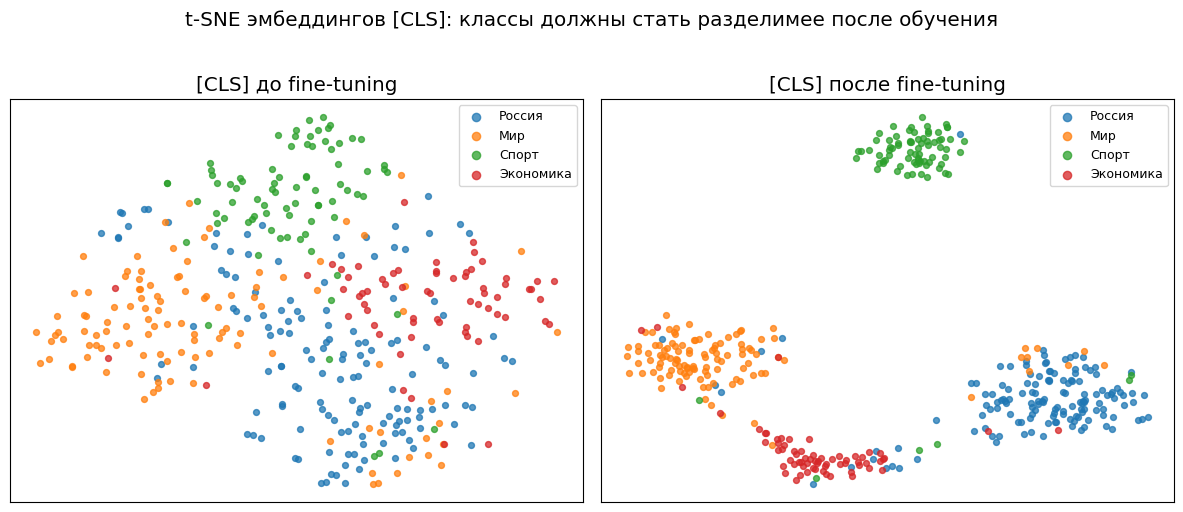

Что смотреть: после fine-tuning кластеры обычно плотнее и меньше пересекаются. Пересечения ≈ путаемые классы — полезный намёк для разбора ошибок.


In [11]:
# perplexity ~ число «соседей», на которое смотрит t-SNE; для 400 точек 30 — разумный дефолт
PERPLEXITY = 30

tsne = TSNE(
    n_components=2,
    perplexity=PERPLEXITY,
    init="pca",
    learning_rate="auto",
    random_state=SEED,
)

# Важно: считаем две проекции отдельно — иначе сравнение «до/после» смешается
Z_before = tsne.fit_transform(X_before)
Z_after = TSNE(
    n_components=2,
    perplexity=PERPLEXITY,
    init="pca",
    learning_rate="auto",
    random_state=SEED,
).fit_transform(X_after)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, Z, title in [
    (axes[0], Z_before, "[CLS] до fine-tuning"),
    (axes[1], Z_after, "[CLS] после fine-tuning"),
]:
    for lab, name in LABEL_NAMES.items():
        mask = y_tsne == lab
        ax.scatter(Z[mask, 0], Z[mask, 1], s=18, alpha=0.75, label=name)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(markerscale=1.4, fontsize=9)

plt.suptitle(
    "t-SNE эмбеддингов [CLS]: классы должны стать разделимее после обучения",
    y=1.02,
)
plt.tight_layout()
plt.show()

print(
    "Что смотреть: после fine-tuning кластеры обычно плотнее и меньше пересекаются. "
    "Пересечения ≈ путаемые классы — полезный намёк для разбора ошибок."
)

## 5. Задание: Классификация тональности твитов

Текст лежит в колонке `ttext`, метка — в `ttype`. В одном файле `ttype = 1` (позитив), в другом `ttype = -1` (негатив). Автора, дату и счётчики ретвитов в модель не подаём.

Следующая ячейка уже собирает таблицу: `text` из `ttext`, `label` — позитив `1` и негатив `0`. Так ждут и `CrossEntropyLoss` внутри `train_epochs`, и `AutoModelForSequenceClassification`. Дубликаты и тексты с двумя разными метками выкинуты: иначе один и тот же твит мог бы попасть и в train, и в test.

В корпусе сотни тысяч строк. Для занятия оставлена стратифицированная подвыборка по 4000 твитов каждого класса: одна эпоха успевает пройти, классы остаются равными.

Токенизатор BERT сам режет `@user`, `RT` и ссылки. Базовое решение учите на сыром тексте.

**Train, val, test.** test уже отложен: 15%, стратификация по `label`, `random_state=SEED`. Долю test и seed оставляем как есть — по этому test сравниваем решения.

Из `tweet_train_val_df` сами выделите train и val. Сколько отдать на val, решаете вы. Больше val — устойчивее выбор гиперпараметров, меньше train — модель видит меньше примеров.

На test считайте качество один раз, уже когда модель и гиперпараметры выбраны по val. В `train_epochs` передавайте train и val. Финальные accuracy и macro-F1 на test посчитайте отдельным вызовом `evaluate`. Если test заметно хуже val, конфигурацию слишком сильно подогнали под валидацию.

**Что сделать.**

1. Из `tweet_train_val_df` выделить train и val. Долю val выберите сами. `tweet_test_df` не меняем и не используем, пока модель не выбрана по val.
2. Реализовать `SentimentDataset` по шаблону ниже. По устройству ориентируйтесь на `NewsDataset`.
3. Взять модель `cointegrated/rubert-tiny2` и поставить классификационную голову на два класса (`num_labels=2`). Можно выбрать и любую другую доступную модель — тогда, возможно, придётся разобраться в её документации. Токенизатор и модель загружайте из одного имени и передайте в `from_pretrained` уже объявленный `MODEL_LOAD_KWARGS`: на MPS без `attn_implementation="eager"` обучение падает.
4. Подобрать гиперпараметры по val: `max_length`, размер батча, lr, число эпох, freeze или full fine-tune. Как заморозить тело и оставить голову, показано в режиме freeze выше. По желанию включите `label_smoothing` и `use_scheduler` — это аргументы `train_epochs`.
5. Один раз вызвать `evaluate` на test и записать accuracy и macro-F1.

**Функции выше.** `set_requires_grad`, `evaluate` и `train_epochs` подходят и для 4 рубрик новостей, и для этой тональности. Число классов задаёт голова модели. Батч — словарь тензоров, как у `NewsDataset`: `input_ids`, `attention_mask`, при необходимости `token_type_ids`, и `labels` типа `torch.long` со значениями `0` и `1` (после `DataLoader` форма `[B]`).

Заголовки новостей короткие (`MAX_LENGTH = 32`). Твит обычно длиннее: маленький `max_length` обрежет текст, из-за этого подберите длину заново.

У сбалансированных двух классов случайный ответ даёт accuracy и macro-F1 около 0.5. Рабочая модель должна быть заметно выше.


In [12]:
# Два csv уже лежат в data/. Если файла нет — качаем с Google Drive,
# id стоит в ссылке между "/d/" и "/view". Метку берём из ttype, а не из имени файла.
TWEET_FILES = [
    (Path("data/positive.csv"), "11MC8q4owLXcsoFHigwFGTVp5Iq81FcGm"),
    (Path("data/negative.csv"), "120V84GUyoEZFYT4kCecLpDtQZuRRJPd4"),
]

for path, file_id in TWEET_FILES:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        url = f"https://drive.google.com/uc?export=download&id={file_id}&confirm=t"
        print("Скачиваем", path, "...")
        urllib.request.urlretrieve(url, path)

frames = [pd.read_csv(path) for path, _ in TWEET_FILES]
tweets = pd.concat(frames, ignore_index=True)
tweets = tweets.dropna(subset=["ttext", "ttype"]).copy()
tweets["text"] = tweets["ttext"].astype(str).str.strip()
tweets = tweets.loc[tweets["text"].ne("")].copy()
# В корпусе позитив = 1, негатив = -1.
# Для loss и головы: позитив остаётся 1, негатив становится 0.
tweets["label"] = (tweets["ttype"] == 1).astype(int)

# Один и тот же текст с двумя метками или дубликат мог бы попасть и в train, и в test.
label_per_text = tweets.groupby("text")["label"].nunique()
conflict_texts = label_per_text[label_per_text > 1].index
tweets = tweets.loc[~tweets["text"].isin(conflict_texts)].drop_duplicates(
    subset=["text"]
)

# Несколько тысяч на класс: эпоха укладывается в занятие, а классы остаются равными.
N_PER_CLASS = 4000
parts = [
    frame.sample(n=N_PER_CLASS, random_state=SEED)
    for _, frame in tweets.groupby("label")
]
sample_df = (
    pd.concat(parts, ignore_index=True)
    .sample(frac=1.0, random_state=SEED)
    .reset_index(drop=True)
)

# test общий для всей группы: 15% и SEED фиксированы, эту ячейку оставляем как есть.
# Val из остатка выделяете сами в следующей ячейке: долю выбираете вы.
# Имена с префиксом tweet_: в ноутбуке уже есть train_df / train_loader для новостей.
tweet_train_val_df, tweet_test_df = train_test_split(
    sample_df,
    test_size=0.15,
    stratify=sample_df["label"],
    random_state=SEED,
)
tweet_train_val_df = tweet_train_val_df.reset_index(drop=True)
tweet_test_df = tweet_test_df.reset_index(drop=True)
print(
    f"train+val {len(tweet_train_val_df)} | test {len(tweet_test_df)} | "
    f"баланс test {tweet_test_df['label'].value_counts().to_dict()}"
)


train+val 6800 | test 1200 | баланс test {0: 600, 1: 600}


In [ ]:
# TODO: из tweet_train_val_df выделите tweet_train_df и tweet_val_df.
# Стратификация по label, random_state=SEED.
# Долю val выбираете сами.
# tweet_test_df не используем, пока модель не выбрана по val.


class SentimentDataset(Dataset):
    """Один твит → словарь тензоров для классификации тональности."""

    def __init__(self, frame: pd.DataFrame, tokenizer, max_length: int):
        # TODO: сохранить тексты, метки 0/1, tokenizer и max_length.
        # Ожидаются колонки frame["text"] и frame["label"].
        raise NotImplementedError

    def __len__(self):
        # TODO
        raise NotImplementedError

    def __getitem__(self, idx):
        # TODO: токенизировать текст с индексом idx.
        # Верните словарь тензоров в том же виде, что NewsDataset,
        # иначе train_epochs и evaluate не прочитают батч:
        #   input_ids, attention_mask, labels
        # labels — скаляр torch.long (0 или 1), без размерности батча.
        # token_type_ids добавляйте только если их вернул tokenizer и модель их принимает.
        raise NotImplementedError


# TODO: загрузить tokenizer и модель из одного имени.
# По умолчанию cointegrated/rubert-tiny2, num_labels=2, и **MODEL_LOAD_KWARGS в from_pretrained.
# Свои max_length и batch size — отдельные переменные, не MAX_LENGTH из задачи про новости.

# TODO: DataLoader для tweet_train_df и tweet_val_df (shuffle только у train).
# test_loader соберите из tweet_test_df здесь же, но в train_epochs его не передавайте.
# Проверьте один батч: labels формы [B] и значения только 0 и 1.

# TODO: обучить через train_epochs. Модель, lr, эпохи, freeze/full
# выбирайте по val macro-F1.

# TODO: один раз в самом конце, когда конфигурация уже выбрана:
# test_metrics = evaluate(<ваша модель>, test_loader)
# print(test_metrics)


## 6. Немного GPT: генерация текста

**Мотивация.** BERT-подобные модели — энкодеры: удобны для классификации, поиска, NER. GPT-подобные (decoder-only) на инференсе генерируют текст **авторегрессивно** (токен за токеном), как на лекции.

**Как работает алгоритм.**
1. `pipeline("text-generation")` загружает маленькую модель семейства Qwen3 (`Qwen/Qwen3-0.6B`) и на каждом шаге предсказывает следующий токен.
2. `temperature` регулирует «остроту» распределения: ниже → скучнее и стабильнее, выше → разнообразнее, но шумнее.
3. Обучать decoder-only LLM с нуля на семинаре не успеем и не нужно — только inference.

**Когда применять.**
- Хорошо подходит, когда: нужна генерация, продолжение текста, черновик, диалог.
- Плохо подходит, когда: нужен стабильный класс / извлечение сущностей — туда лучше BERT-подобные модели.

### Параметры генерации (`model.generate` / `pipeline`)

На каждом шаге модель выдаёт логиты по словарю; параметры ниже решают, **как из них выбрать следующий токен** и **когда остановиться**.

#### Длина и остановка
- **`max_new_tokens`** — сколько *новых* токенов максимум дописать (удобнее, чем `max_length`: не зависит от длины промпта).
- **`min_new_tokens`** / **`min_length`** — не заканчивать раньше (модель не «сдаётся» на EOS слишком рано).
- **`max_length`** — жёсткий потолок *всей* последовательности (промпт + ответ); с `max_new_tokens` обычно не смешивают.
- **`eos_token_id`**, **`pad_token_id`** — id конца и паддинга; для decoder-only часто `pad_token_id = eos_token_id`.

#### Жадный поиск vs сэмплинг
- **`do_sample=False`** — greedy / beam: детерминированно берём лучшие кандидаты.
- **`do_sample=True`** — сэмплируем из распределения (нужны `temperature` / `top_k` / `top_p`).
- **`num_beams`** — beam search: держим $k$ лучших частично построенных строк (`1` = greedy).
- **`early_stopping`** — в beam search раньше обрывать, когда набралось достаточно законченных гипотез.
- **`length_penalty`** — в beam search штраф/бонус за длину ($>1$ длиннее, $<1$ короче).
- **`num_return_sequences`** — сколько разных продолжений вернуть (при сэмплинге или beam > 1).

#### «Креативность» распределения (только при `do_sample=True`)
- **`temperature`** — делит логиты перед softmax: $<1$ острее (стабильнее), $>1$ площе (разнообразнее, больше бреда).
- **`top_k`** — оставляем только $k$ самых вероятных токенов, остальное обнуляем.
- **`top_p`** (nucleus) — оставляем минимальный набор токенов с суммарной вероятностью $\ge p$ (например $0.9$).
- **`typical_p`** — отбор «типичных» токенов (альтернатива top-p; реже нужен на старте).

#### Повторы и запреты
- **`repetition_penalty`** — $>1$ понижает вероятность уже встречавшихся токенов (меньше зацикливания).
- **`no_repeat_ngram_size`** — запрет повторять n-граммы длины $n$ (например $3$).
- **`bad_words_ids`** — список id токенов/фраз, которые нельзя генерировать.

#### Реже на семинаре, но полезно знать
- **`num_beam_groups`** + **`diversity_penalty`** — diverse beam search (несколько «групп» лучей).
- **`penalty_alpha`** (+ `top_k`) — contrastive search: баланс правдоподобия и отличия от контекста.
- **`guidance_scale`** — classifier-free guidance (если модель/пайплайн это поддерживает).

В ячейке ниже собираем типичный набор в словарь и сравниваем два `temperature` при одинаковых остальных настройках.


In [13]:
# Маленький Qwen3: только инференс, без обучения.
# Для семинара берём маленькую — Qwen3-0.6B (~0.6B параметров).
model_id = "Qwen/Qwen3-0.6B"
# Тот же device, что выбран в начале: cuda, mps или cpu.
# eager attention — тот же обход, что у RuBERT: на MPS SDPA может упасть.
gen = pipeline(
    "text-generation",
    model=model_id,
    tokenizer=model_id,
    device=device,
    model_kwargs=dict(MODEL_LOAD_KWARGS),
)

# Instruct-модель: чат-шаблон и enable_thinking=False.
# Шаблон всё равно вставляет пустые теги <think></think>, рассуждения внутри них нет.
# system задаёт роль/стиль; user — конкретный запрос
messages = [
    {
        "role": "system",
        "content": "Ты — краткий новостной редактор. Пиши по-русски, без списков и без рассуждений «вслух».",
    },
    {
        "role": "user",
        "content": "Продолжи одной-двумя фразами: Сегодня учёные сообщили, что",
    },
]
prompt = gen.tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)

# Базовый набор параметров генерации (см. markdown выше).
# Меняем только temperature между двумя прогонами — остальное фиксируем.
gen_kwargs = dict(
    # --- длина и остановка ---
    max_new_tokens=60,  # сколько новых токенов дописать
    min_new_tokens=1,  # не обрывать слишком рано
    # max_length не задаём: конфликтует с max_new_tokens
    pad_token_id=gen.tokenizer.eos_token_id,
    eos_token_id=gen.tokenizer.eos_token_id,
    # --- режим выбора токена ---
    do_sample=True,  # False → greedy/beam; True → сэмплинг
    num_beams=1,  # >1 включает beam search (обычно с do_sample=False)
    early_stopping=False,  # имеет смысл при num_beams > 1
    length_penalty=1.0,  # >1 длиннее ответы (beam); 1.0 = нейтрально
    num_return_sequences=1,  # сколько продолжений вернуть
    # --- форма распределения (работают при do_sample=True) ---
    # temperature задаём отдельно в каждом вызове
    top_k=50,  # кандидаты — только top-50 токенов
    top_p=0.9,  # nucleus: масса вероятности ≥ 0.9
    typical_p=1.0,  # 1.0 = выключено; <1 — typical decoding
    # --- против повторов ---
    repetition_penalty=1.1,  # >1 штрафует уже сказанное
    no_repeat_ngram_size=0,  # 0 = выкл.; 3 = запрет повтор 3-грамм
    # --- редко нужные на семинаре (оставляем «выкл.») ---
    num_beam_groups=1,  # >1 + diversity_penalty → diverse beam
    diversity_penalty=0.0,
    # penalty_alpha=0.0,  # contrastive search; раскомментируйте вместе с top_k
    # bad_words_ids=None,  # список запрещённых токен-id
)

# Все параметры — в одном GenerationConfig, без отдельных kwargs generate.
# Иначе pipeline подмешивает свой max_length=20, и он конфликтует с max_new_tokens.
# clean_up_tokenization_spaces=False: у BPE-токенизатора Qwen чистка пробелов портит текст.
# temperature низкая → более предсказуемое продолжение
out_low = gen(
    prompt,
    generation_config=GenerationConfig(temperature=0.7, **gen_kwargs),
    clean_up_tokenization_spaces=False,
)
# temperature повыше → более «креативно», но риск ерунды
out_high = gen(
    prompt,
    generation_config=GenerationConfig(temperature=1.3, **gen_kwargs),
    clean_up_tokenization_spaces=False,
)

print("=== temperature=0.7 ===")
print(out_low[0]["generated_text"])
print("\n=== temperature=1.3 ===")
print(out_high[0]["generated_text"])


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'repetition_penalty', 'early_stopping', 'min_new_tokens', 'diversity_penalty', 'eos_token_id', 'top_p', 'typical_p', 'num_return_sequences', 'num_beam_groups', 'length_penalty', 'temperature', 'max_new_tokens', 'no_repeat_ngram_size', 'num_beams', 'do_sample', 'top_k'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=1) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

=== temperature=0.7 ===
<|im_start|>system
Ты — краткий новостной редактор. Пиши по-русски, без списков и без рассуждений «вслух».<|im_end|>
<|im_start|>user
Продолжи одной-двумя фразами: Сегодня учёные сообщили, что<|im_end|>
<|im_start|>assistant
<think>

</think>

Сегодня учёные сообщили, что вирусы могут синтезировать новые формы жизни.

=== temperature=1.3 ===
<|im_start|>system
Ты — краткий новостной редактор. Пиши по-русски, без списков и без рассуждений «вслух».<|im_end|>
<|im_start|>user
Продолжи одной-двумя фразами: Сегодня учёные сообщили, что<|im_end|>
<|im_start|>assistant
<think>

</think>

Сегодня учёные сообщили, что звуковые волны нашёл у старых мусорных башмаков из корабля НИКМ-170, которые оказал священное влияние на электромагнитную


### Разметка ChatML (спецтокены в `prompt`)

Это разметка **ChatML**: диалог упакован в один текст, который видит модель.

- `<|im_start|>` — начало сообщения. Дальше обычно роль: `user`, `assistant` или `system`.
- `user` / `assistant` / `system` — кто говорит.
- `<|im_end|>` — конец этого сообщения.
- `<think>` … `</think>` — блок внутренних рассуждений Qwen. В ячейке выше стоит `enable_thinking=False`, поэтому блок пустой: теги в сыром тексте есть, рассуждения внутри нет. Продолжение фразы идёт сразу после `</think>`.

`pipeline` возвращает весь `prompt` плюс новые токены, поэтому спецтокены видны. В обычном чате их скрывают.
